# ReviewRadar — Review Helpfulness Analysis

**Goal:** predict how helpful a review sentence is for a purchase decision.

**Dataset:** Amazon's *Helpful Sentences from Reviews* benchmark — 20,000 training sentences + 2,000 test sentences, with human helpfulness scores from 0 to 2.

In [1]:
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
TRAIN_URL = "https://helpful-sentences-from-reviews.s3.amazonaws.com/train.json"
TEST_URL = "https://helpful-sentences-from-reviews.s3.amazonaws.com/test.json"

def load_json_lines(url):
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    return pd.DataFrame([json.loads(x) for x in r.text.splitlines() if x.strip()])

train = load_json_lines(TRAIN_URL)
test = load_json_lines(TEST_URL)

print("Train:", train.shape)
print("Test :", test.shape)

Train: (20000, 5)
Test : (2000, 5)


In [3]:
def clean(df):
    df = df[["asin", "sentence", "helpful", "product_title"]].copy()
    df["sentence"] = df["sentence"].fillna("").astype(str).str.replace(r"<[^>]+>", " ", regex=True)
    df["sentence"] = df["sentence"].str.replace(r"\s+", " ", regex=True).str.strip()
    df["helpful"] = pd.to_numeric(df["helpful"], errors="coerce")
    df = df.dropna(subset=["helpful"])
    df = df[df["sentence"].str.len() > 0]
    df = df.drop_duplicates(subset=["asin", "sentence"])
    df["length"] = df["sentence"].str.len()
    df["text"] = df["sentence"]
    return df.reset_index(drop=True)

train = clean(train)
test = clean(test)
print("Clean train:", train.shape)
print("Clean test :", test.shape)


Clean train: (19999, 6)
Clean test : (2000, 6)


## EDA
The most useful quick checks are the helpfulness distribution and the relationship between sentence length and helpfulness.

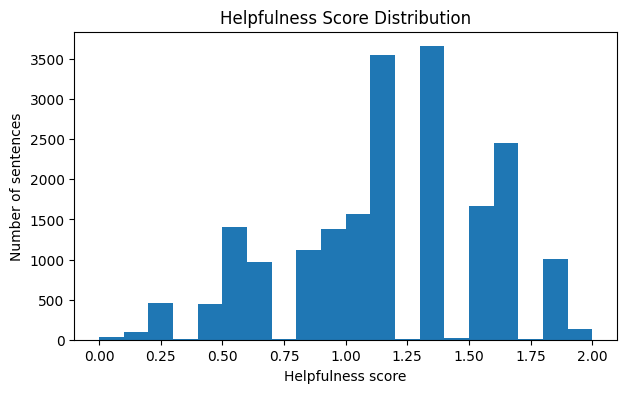

In [4]:
plt.figure(figsize=(7,4))
plt.hist(train["helpful"], bins=20)
plt.xlabel("Helpfulness score")
plt.ylabel("Number of sentences")
plt.title("Helpfulness Score Distribution")
plt.show()

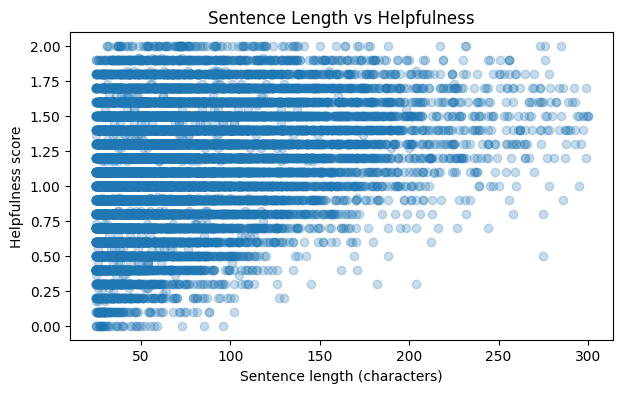

In [5]:
plt.figure(figsize=(7,4))
plt.scatter(train["length"], train["helpful"], alpha=0.25)
plt.xlabel("Sentence length (characters)")
plt.ylabel("Helpfulness score")
plt.title("Sentence Length vs Helpfulness")
plt.show()

In [6]:
print("Average helpfulness:", round(train["helpful"].mean(), 3))
print("Average sentence length:", round(train["length"].mean(), 1))
print("Length correlation:", round(train[["length", "helpful"]].corr().iloc[0,1], 3))

Average helpfulness: 1.161
Average sentence length: 75.9
Length correlation: 0.286


## Preprocessing & Features
We use the review sentence together with its product title as text context. TF-IDF converts that text into numerical features. No helpfulness information is used as an input feature.

In [7]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=15000, sublinear_tf=True)
X_train = vectorizer.fit_transform(train["text"])
X_test = vectorizer.transform(test["text"])

print("TF-IDF features:", X_train.shape[1])

TF-IDF features: 15000


## Model Development
We compare a simple mean baseline with **Ridge Regression**. Ridge is appropriate because helpfulness is a continuous 0–2 score and TF-IDF creates many sparse, correlated text features.

**Why Ridge:** fast, simple, regularized, and a strong lightweight NLP model. The original benchmark also reports TF-IDF + Ridge as a useful lightweight baseline.


In [8]:
baseline = np.repeat(train["helpful"].mean(), len(test))
baseline_mae = mean_absolute_error(test["helpful"], baseline)

model = Ridge(alpha=2.0)
model.fit(X_train, train["helpful"])
pred = np.clip(model.predict(X_test), 0, 2)


In [9]:
true = test["helpful"].to_numpy()
mae = mean_absolute_error(true, pred)
mse = mean_squared_error(true, pred)
r2 = r2_score(true, pred)
pearson = pearsonr(true, pred).statistic
within_half = np.mean(np.abs(true - pred) <= 0.5) * 100

print(f"Baseline MAE: {baseline_mae:.3f}")
print(f"Ridge MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"R2: {r2:.3f}")
print(f"Pearson correlation: {pearson:.3f}")
print(f"Accuracy within ±0.5: {within_half:.1f}%")


Baseline MAE: 0.328
Ridge MAE: 0.223
MSE: 0.084
R2: 0.487
Pearson correlation: 0.723
Accuracy within ±0.5: 91.3%


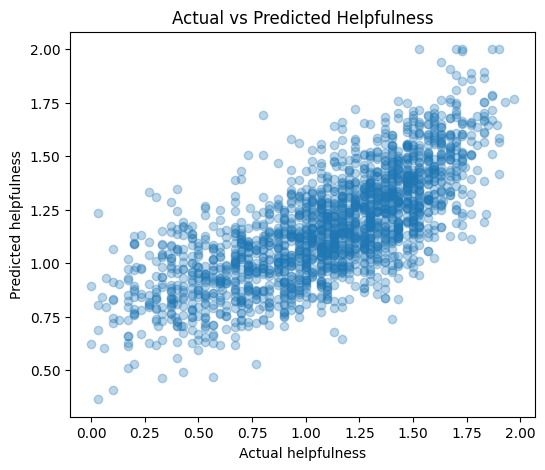

In [10]:
plt.figure(figsize=(6,5))
plt.scatter(true, pred, alpha=0.30)
plt.xlabel("Actual helpfulness")
plt.ylabel("Predicted helpfulness")
plt.title("Actual vs Predicted Helpfulness")
plt.show()

## Result Interpretation
The main evaluation measures are **MAE, MSE, R² and Pearson correlation** because this is a regression task. The **±0.5 accuracy** is a supplementary measure: it shows the percentage of test predictions that are within half a point of the human helpfulness score.

The baseline comparison is important because it shows whether the text model learns useful patterns instead of simply predicting the average score.


In [11]:
results = pd.DataFrame({
    "Metric": ["Baseline MAE", "Ridge MAE", "MSE", "R2", "Pearson", "Accuracy within ±0.5"],
    "Value": [baseline_mae, mae, mse, r2, pearson, within_half]
})
results


,Metric,Value
0,Baseline MAE,0.327562
1,Ridge MAE,0.222621
2,MSE,0.083733
3,R2,0.486724
4,Pearson,0.722755
5,Accuracy within ±0.5,91.350000


### Optional save for Streamlit

In [12]:
import joblib
from pathlib import Path
import json

Path("artifacts").mkdir(exist_ok=True)
joblib.dump({"vectorizer": vectorizer, "model": model}, "artifacts/review_helpfulness_ridge.joblib")
Path("artifacts/metrics.json").write_text(json.dumps({
    "mae": float(mae),
    "mse": float(mse),
    "r2": float(r2),
    "pearson": float(pearson),
    "within_half_accuracy": float(within_half),
    "baseline_mae": float(baseline_mae),
    "train_rows": int(len(train)),
    "test_rows": int(len(test)),
    "features": int(X_train.shape[1])
}, indent=2))
print("Model saved for Streamlit.")


Model saved for Streamlit.
